In [1]:
import pandas as pd

In [2]:
delivery = pd.read_csv('delivery_data.csv')
delivery.head()

,Distance_km,Prep_Time_min,Courier_Experience_yrs,Weather,Traffic_Level,Vehicle_Type,Delivery_Time_min,Is_Late
0,5.993428,11.624109,7,NaN,High,Scooter,44.013542,0
1,4.723471,14.277407,2,Sunny,High,Car,35.527712,0
2,6.295377,11.037900,9,Rainy,High,Scooter,48.567934,1
3,8.046060,13.460192,7,Sunny,High,Car,50.452710,1
4,4.531693,5.531927,7,Rainy,Medium,Bicycle,47.632817,1


In [3]:
X_delivery = delivery.drop('Delivery_Time_min', axis=1)
X_delivery.shape

(2000, 7)

In [4]:
y_delivery = delivery['Delivery_Time_min']
y_delivery.shape

(2000,)

In [5]:
from sklearn.model_selection import train_test_split
Xtrain,Xtest,ytrain,ytest = train_test_split(X_delivery,y_delivery, random_state=1)

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [8]:
X_delivery.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Distance_km             2000 non-null   float64
 1   Prep_Time_min           1895 non-null   float64
 2   Courier_Experience_yrs  2000 non-null   int64  
 3   Weather                 1893 non-null   object 
 4   Traffic_Level           2000 non-null   object 
 5   Vehicle_Type            2000 non-null   object 
 6   Is_Late                 2000 non-null   int64  
dtypes: float64(2), int64(2), object(3)
memory usage: 109.5+ KB


In [9]:
numeric_features = X_delivery.select_dtypes(include=['int64','float64']).columns
categori_features = X_delivery.select_dtypes(include=['object']).columns

In [10]:
numerical_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

In [11]:
categorical_transformer = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore')) 
])

In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer,numeric_features),
        ('cat',categorical_transformer,categori_features)
    ],
    remainder='passthrough'
)
preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'mean'
,fill_value,None


In [13]:
X_processed_a= preprocessor.fit_transform(X_delivery)

In [14]:
feature_names = preprocessor.get_feature_names_out()
feature_names

array(['num__Distance_km', 'num__Prep_Time_min',
       'num__Courier_Experience_yrs', 'num__Is_Late',
       'cat__Weather_Foggy', 'cat__Weather_Rainy', 'cat__Weather_Snowy',
       'cat__Weather_Sunny', 'cat__Traffic_Level_High',
       'cat__Traffic_Level_Jam', 'cat__Traffic_Level_Low',
       'cat__Traffic_Level_Medium', 'cat__Vehicle_Type_Bicycle',
       'cat__Vehicle_Type_Car', 'cat__Vehicle_Type_Scooter'], dtype=object)

In [15]:
X_processed_a.shape

(2000, 15)

In [16]:
len(feature_names)

15

In [17]:
X_processed = pd.DataFrame(X_processed_a , columns=feature_names)
X_processed.head()

,num__Distance_km,num__Prep_Time_min,num__Courier_Experience_yrs,num__Is_Late,cat__Weather_Foggy,cat__Weather_Rainy,cat__Weather_Snowy,cat__Weather_Sunny,cat__Traffic_Level_High,cat__Traffic_Level_Jam,cat__Traffic_Level_Low,cat__Traffic_Level_Medium,cat__Vehicle_Type_Bicycle,cat__Vehicle_Type_Car,cat__Vehicle_Type_Scooter
0,0.457790,-0.708395,0.848302,-1.103311,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-0.191456,-0.156716,-0.884695,-1.103311,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.612156,-0.830281,1.541500,0.906363,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.507165,-0.326633,0.848302,0.906363,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.289499,-1.975095,0.848302,0.906363,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


In [24]:
from sklearn.linear_model import LinearRegression

In [21]:
model=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('regressor',LinearRegression())
])
model

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [22]:
model.fit(Xtrain , ytrain)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [23]:
y_predict = model.predict(Xtest)

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

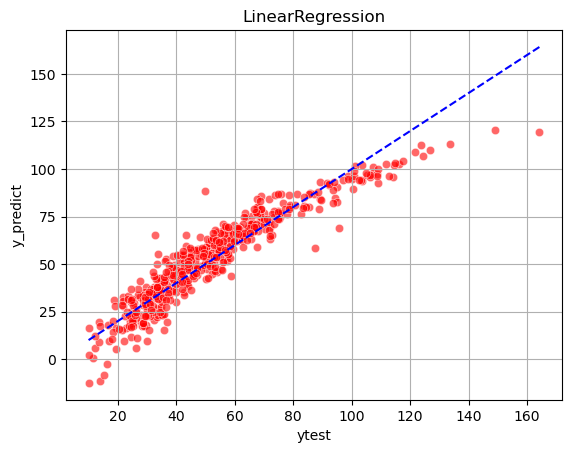

In [27]:
sns.scatterplot(x=ytest , y=y_predict , alpha=0.6 , color='red')
plt.plot([ytest.min() , ytest.max()],
         [ytest.min() , ytest.max()],
         color='blue' , linestyle='--')
plt.xlabel('ytest')
plt.ylabel('y_predict')
plt.title('LinearRegression')
plt.grid(True)
plt.show()